In [3]:
!pip install -q transformers datasets evaluate peft accelerate bitsandbytes

In [4]:
import torch
import time
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model, TaskType
import evaluate
import numpy as np

In [5]:
dataset = load_dataset("imdb")
tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2-0.5B",
    trust_remote_code=True
)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

... (2 outputs left out)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [6]:
def preprocess(examples):
    return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=512)

tokenized = dataset.map(preprocess, batched=True)
tokenized = tokenized.rename_column("label", "labels")
tokenized.set_format("torch")

accuracy = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy.compute(predictions=predictions, references=labels)

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [7]:
print("Start Full fine-tuning")
model_full = AutoModelForSequenceClassification.from_pretrained(
    "Qwen/Qwen2-0.5B",
    num_labels=2,
    dtype=torch.bfloat16,
    trust_remote_code=True
)

model_full.config.pad_token_id = tokenizer.pad_token_id
model_full.config.use_cache = False

model_full.gradient_checkpointing_enable()

training_args_full = TrainingArguments(
    output_dir="./qwen2-full",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=5e-5,
    eval_steps=500,
    logging_steps=100,
    bf16=True,
    report_to="none",
)

trainer_full = Trainer(
    model=model_full,
    args=training_args_full,
    train_dataset=tokenized["train"].shuffle(seed=42).select(range(10000)),
    eval_dataset=tokenized["test"].shuffle(seed=42).select(range(2000)),
    compute_metrics=compute_metrics,
)

start = time.time()
torch.cuda.reset_peak_memory_stats()
trainer_full.train()
full_time = time.time() - start
full_mem = torch.cuda.max_memory_allocated() / 1e9
full_acc = trainer_full.evaluate()["eval_accuracy"]

print(f"Full Fine-tuning: Time: {full_time/60:.1f} min | Memory: {full_mem:.1f} GB | Acc: {full_acc*100:.1f}%")
del model_full, trainer_full
torch.cuda.empty_cache()

Start Full fine-tuning


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss
100,3.009139
200,0.959368
300,0.672228


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Full Fine-tuning: Time: 63.8 min | Memory: 6.0 GB | Acc: 94.4%


In [8]:
print("Start LoRA")
model_lora = AutoModelForSequenceClassification.from_pretrained(
    "Qwen/Qwen2-0.5B",
    num_labels=2,
    dtype=torch.bfloat16,
    trust_remote_code=True
)

model_lora.config.pad_token_id = tokenizer.pad_token_id
model_lora.config.use_cache = False

peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
)
model_lora = get_peft_model(model_lora, peft_config)
model_lora.print_trainable_parameters()

training_args_lora = TrainingArguments(
    output_dir="./qwen2-lora",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=5e-5,
    eval_steps=500,
    logging_steps=100,
    bf16=True,
    report_to="none",
    gradient_checkpointing=True
)

trainer_lora = Trainer(
    model=model_lora,
    args=training_args_lora,
    train_dataset=tokenized["train"].shuffle(seed=42).select(range(10000)),
    eval_dataset=tokenized["test"].shuffle(seed=42).select(range(2000)),
    compute_metrics=compute_metrics,
)

start = time.time()
torch.cuda.reset_peak_memory_stats()
trainer_lora.train()
lora_time = time.time() - start
lora_mem = torch.cuda.max_memory_allocated() / 1e9
lora_acc = trainer_lora.evaluate()["eval_accuracy"]

print(f"LoRA: Time: {lora_time/60:.1f} min | Memory: {lora_mem:.1f} GB | Acc: {lora_acc*100:.1f}%")

Start LoRA


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2-0.5B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,083,136 || all params: 495,117,696 || trainable%: 0.2188


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss
100,3.209248
200,1.501882
300,1.472237


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


LoRA: Time: 53.2 min | Memory: 3.1 GB | Acc: 91.8%


In [9]:
!pip install -q matplotlib

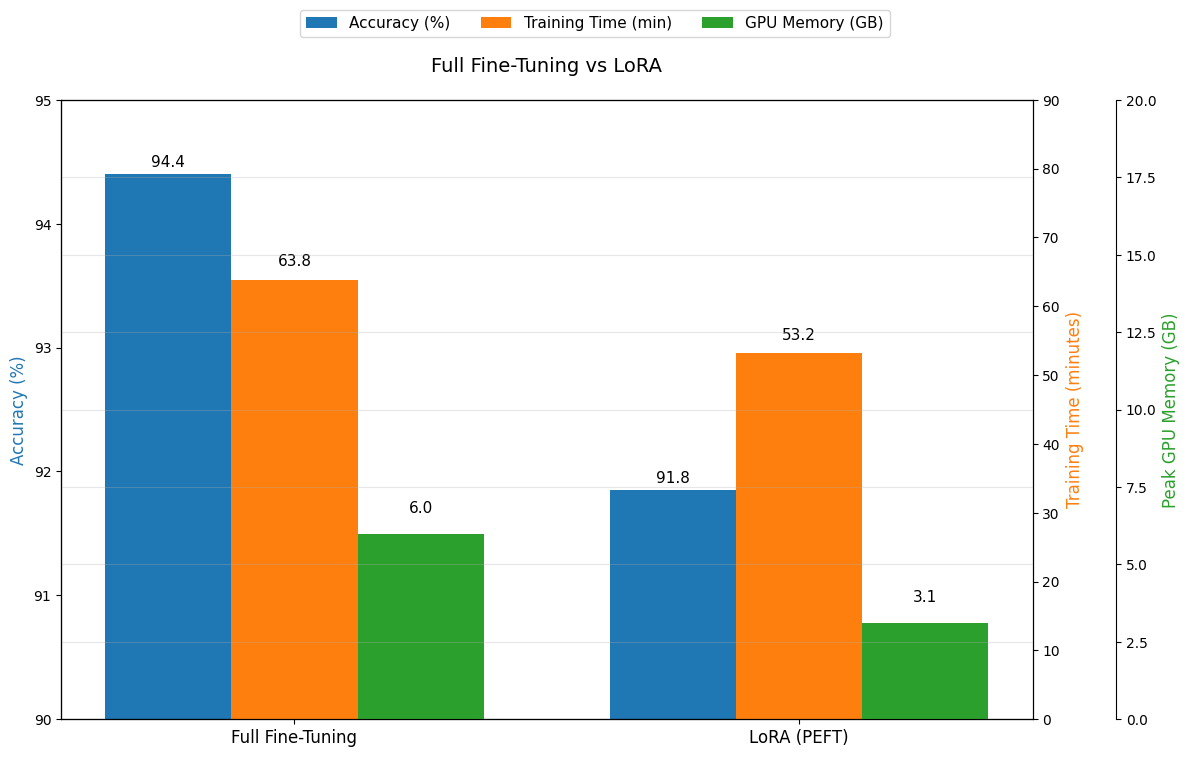

In [10]:
import matplotlib.pyplot as plt

methods = ['Full Fine-Tuning', 'LoRA (PEFT)']
accuracy = [full_acc*100, lora_acc*100]
time_min = [full_time/60, lora_time/60]
memory_gb = [full_mem, lora_mem]

x = np.arange(len(methods))
width = 0.25

fig, ax1 = plt.subplots(figsize=(12, 8))

# Accuracy bars
bars1 = ax1.bar(x - width, accuracy, width, label='Accuracy (%)', color='#1f77b4')
ax1.set_ylabel('Accuracy (%)', color='#1f77b4', fontsize=12)
ax1.set_ylim(90, 95)

# Time bars (secondary axis)
ax2 = ax1.twinx()
bars2 = ax2.bar(x, time_min, width, label='Training Time (min)', color='#ff7f0e')
ax2.set_ylabel('Training Time (minutes)', color='#ff7f0e', fontsize=12)
ax2.set_ylim(0, 90)

# Memory bars
ax3 = ax1.twinx()
ax3.spines['right'].set_position(('outward', 60))
bars3 = ax3.bar(x + width, memory_gb, width, label='GPU Memory (GB)', color='#2ca02c')
ax3.set_ylabel('Peak GPU Memory (GB)', color='#2ca02c', fontsize=12)
ax3.set_ylim(0, 20)

ax1.set_title('Full Fine-Tuning vs LoRA', fontsize=14, pad=20)
ax1.set_xticks(x)
ax1.set_xticklabels(methods, fontsize=12)

def autolabel(bars, ax, offset=0):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3 + offset),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11)

autolabel(bars1, ax1)
autolabel(bars2, ax2, 5)
autolabel(bars3, ax3, 10)

fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.95), ncol=3, fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.grid(axis='y', alpha=0.3)
plt.savefig('full_vs_lora_comparison.png', dpi=300, bbox_inches='tight')
plt.show()